# PathSnap – Exploratory Data Analysis (EDA)

**Owner:** P2 – EDA & Models
**Purpose:** Inspect the permitted development data, GPS trajectories, road-network files, data quality, and geographic patterns before model experimentation.

> **Data-integrity rule:** This notebook only loads `train` and `student_test`. Evaluator-testing trips are never inspected, loaded, plotted or used during development.

## Expected raw file formats
- `.track`: whitespace-separated `longitude latitude timestamp` (no header)
- `.nodes`: whitespace-separated `longitude latitude` (no header)
- `.arcs`: whitespace-separated `from_node_id to_node_id` (no header)
- `.route`: chronological `arc_id` values (no header)

The dataset guide gives these as the general formats; the checks below verify file counts, row counts and data types instead of assuming every trip is identical.

## 1. Setup and configuration
Works locally (repo root or `eda/` folder, data in `data/raw/`) and on Colab (repo cloned or data on Drive).

In [1]:
from pathlib import Path
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "features").is_dir() and (p / "README.md").exists():
            return p
    return Path.cwd()


def is_dataset_root(p):
    return p.exists() and (p / "train").is_dir() and (p / "student_test").is_dir()


ROOT = find_repo_root()
candidate_roots = [
    ROOT / "data" / "raw",
    Path("/content/PathSnap/data/raw"),
    Path("/content/drive/MyDrive/Student folder/Student folder"),
    Path("/content/drive/MyDrive/Student folder"),
    Path("/content/drive/MyDrive/PathSnap/Student folder"),
]
DATA_ROOT = next((p for p in candidate_roots if is_dataset_root(p)), None)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find the dataset. Put train/ and student_test/ in data/raw/ "
        "or edit candidate_roots above.")

OUT_DIR = ROOT / "results" / "eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repo root:   ", ROOT)
print("Dataset root:", DATA_ROOT)
print("Outputs:     ", OUT_DIR)

PARTITIONS = {
    "train": DATA_ROOT / "train",
    "student_test": DATA_ROOT / "student_test",
}

MAP_PARTITION = "train"
MAP_TRIP = "train/00000005"   # set to None to use the first train trip

Repo root:    /home/user/PathSnap
Dataset root: /home/user/PathSnap/data/raw
Outputs:      /home/user/PathSnap/results/eda


## 2. Discover files and build a dataset inventory
Searches recursively for the four documented extensions and reports file availability and sizes.

In [2]:
EXTENSIONS = [".track", ".nodes", ".arcs", ".route"]

def discover_partition(partition_name, folder):
    records = []
    if not folder.exists():
        print(f"WARNING: missing partition folder: {folder}")
        return records
    for ext in EXTENSIONS:
        for path in folder.rglob(f"*{ext}"):
            records.append({
                "partition": partition_name,
                "trip_key": str(path.parent.relative_to(folder)),
                "file_type": ext,
                "file_name": path.name,
                "path": path,
                "size_bytes": path.stat().st_size,
            })
    return records

inventory_records = []
for partition, folder in PARTITIONS.items():
    inventory_records.extend(discover_partition(partition, folder))

inventory = pd.DataFrame(inventory_records)
if inventory.empty:
    print("No files found. Check DATA_ROOT and the partition folder structure.")
else:
    display(inventory.drop(columns="path").sort_values(["partition", "trip_key", "file_type"]).head(12))
    print("\nFiles by partition and type:")
    display(inventory.groupby(["partition", "file_type"]).size().unstack(fill_value=0))
    print("\nTotal file size (MB):", round(inventory["size_bytes"].sum() / 1e6, 3))

,partition,trip_key,file_type,file_name,size_bytes
349,student_test,00000000,.arcs,00000000.arcs,176989
339,student_test,00000000,.nodes,00000000.nodes,170840
359,student_test,00000000,.route,00000000.route,881
329,student_test,00000000,.track,00000000.track,81492
347,student_test,00000007,.arcs,00000007.arcs,38998
337,student_test,00000007,.nodes,00000007.nodes,41220
357,student_test,00000007,.route,00000007.route,486
327,student_test,00000007,.track,00000007.track,43575
344,student_test,00000009,.arcs,00000009.arcs,126694
334,student_test,00000009,.nodes,00000009.nodes,134900



Files by partition and type:


file_type,.arcs,.nodes,.route,.track
partition,,,,
student_test,10,10,10,10
train,80,80,80,80



Total file size (MB): 94.106


## 3. Load raw trip files
Trips are grouped by parent directory. Duplicate file types within one trip are flagged.

In [3]:
def read_whitespace(path, expected_cols):
    df = pd.read_csv(path, sep=r"\s+", header=None)
    if df.shape[1] != expected_cols:
        raise ValueError(f"{path}: expected {expected_cols} columns, found {df.shape[1]}")
    return df

def load_trip_files(folder):
    found = {}
    for ext in EXTENSIONS:
        matches = list(folder.glob(f"*{ext}"))
        if len(matches) > 1:
            print(f"WARNING: multiple {ext} files in {folder}; using {matches[0].name}")
        if matches:
            found[ext] = matches[0]
    trip = {"files": found, "folder": folder}
    if ".track" in found:
        trip["track"] = read_whitespace(found[".track"], 3).set_axis(["longitude", "latitude", "timestamp"], axis=1)
    if ".nodes" in found:
        trip["nodes"] = read_whitespace(found[".nodes"], 2).set_axis(["longitude", "latitude"], axis=1)
    if ".arcs" in found:
        trip["arcs"] = read_whitespace(found[".arcs"], 2).set_axis(["from_node_id", "to_node_id"], axis=1)
    if ".route" in found:
        trip["route"] = read_whitespace(found[".route"], 1).set_axis(["arc_id"], axis=1)
    return trip

trips = {}
for partition, folder in PARTITIONS.items():
    trip_dirs = sorted({p.parent for p in folder.rglob("*") if p.is_file() and p.suffix in EXTENSIONS})
    for trip_dir in trip_dirs:
        key = f"{partition}/{trip_dir.relative_to(folder)}"
        try:
            trips[key] = {"partition": partition, **load_trip_files(trip_dir)}
        except Exception as e:
            print("LOAD ERROR:", key, repr(e))

print("Trips loaded:", len(trips))
print("By partition:", pd.Series([v["partition"] for v in trips.values()]).value_counts().to_dict())

Trips loaded: 90
By partition: {'train': 80, 'student_test': 10}


## 4. Trip-level inventory and basic statistics

In [4]:
trip_rows = []
for key, trip in trips.items():
    track, nodes, arcs, route = (trip.get(k) for k in ["track", "nodes", "arcs", "route"])
    trip_rows.append({
        "trip": key,
        "partition": trip["partition"],
        "gps_observations": len(track) if track is not None else np.nan,
        "road_nodes": len(nodes) if nodes is not None else np.nan,
        "road_arcs": len(arcs) if arcs is not None else np.nan,
        "reference_route_arcs": len(route) if route is not None else np.nan,
        "has_track": track is not None,
        "has_nodes": nodes is not None,
        "has_arcs": arcs is not None,
        "has_route": route is not None,
    })
trip_summary = pd.DataFrame(trip_rows)
display(trip_summary.head(10))
print("Total GPS observations:", int(trip_summary.gps_observations.sum()))
display(trip_summary.groupby("partition")[
    ["gps_observations", "road_nodes", "road_arcs", "reference_route_arcs"]
].describe().round(2).T)

,trip,partition,gps_observations,road_nodes,road_arcs,reference_route_arcs,has_track,has_nodes,has_arcs,has_route
0,train/00000001,train,1315,88809,165790,525,True,True,True,True
1,train/00000002,train,7243,7936,16139,262,True,True,True,True
2,train/00000003,train,821,9138,18028,79,True,True,True,True
3,train/00000004,train,1064,7350,15499,320,True,True,True,True
4,train/00000005,train,1045,898,1579,105,True,True,True,True
5,train/00000006,train,1450,3259,6757,261,True,True,True,True
6,train/00000008,train,3093,4995,10421,173,True,True,True,True
7,train/00000010,train,2711,8502,15715,210,True,True,True,True
8,train/00000011,train,2828,2649,5393,565,True,True,True,True
9,train/00000012,train,1608,16376,38599,205,True,True,True,True


Total GPS observations: 227577


partition                   student_test      train
gps_observations     count         10.00      80.00
                     mean        1916.00    2605.21
                     std         1335.43    3312.35
                     min          262.00     361.00
                     25%          917.75     945.75
                     50%         1420.00    1529.00
                     75%         2872.00    2792.75
                     max         3958.00   19313.00
road_nodes           count         10.00      80.00
                     mean        9068.90   24168.56
                     std         7452.18   32272.30
                     min         1770.00     299.00
                     25%         4908.00    3487.75
                     50%         6596.50    9608.00
                     75%        11844.25   28846.75
                     max        26635.00  155003.00
road_arcs            count         10.00      80.00
                     mean       18504.10   48461.30
                     std        15496.93   64738.84
                     min         3577.00     649.00
                     25%        10292.25    7061.75
                     50%        13145.00   19526.50
                     75%        24818.50   58003.25
                     max        56027.00  307392.00
reference_route_arcs count         10.00      80.00
                     mean         347.70     391.70
                     std          359.57     361.17
                     min           95.00      59.00
                     25%          153.50     168.25
                     50%          250.00     280.00
                     75%          357.75     480.50
                     max         1323.00    2266.00

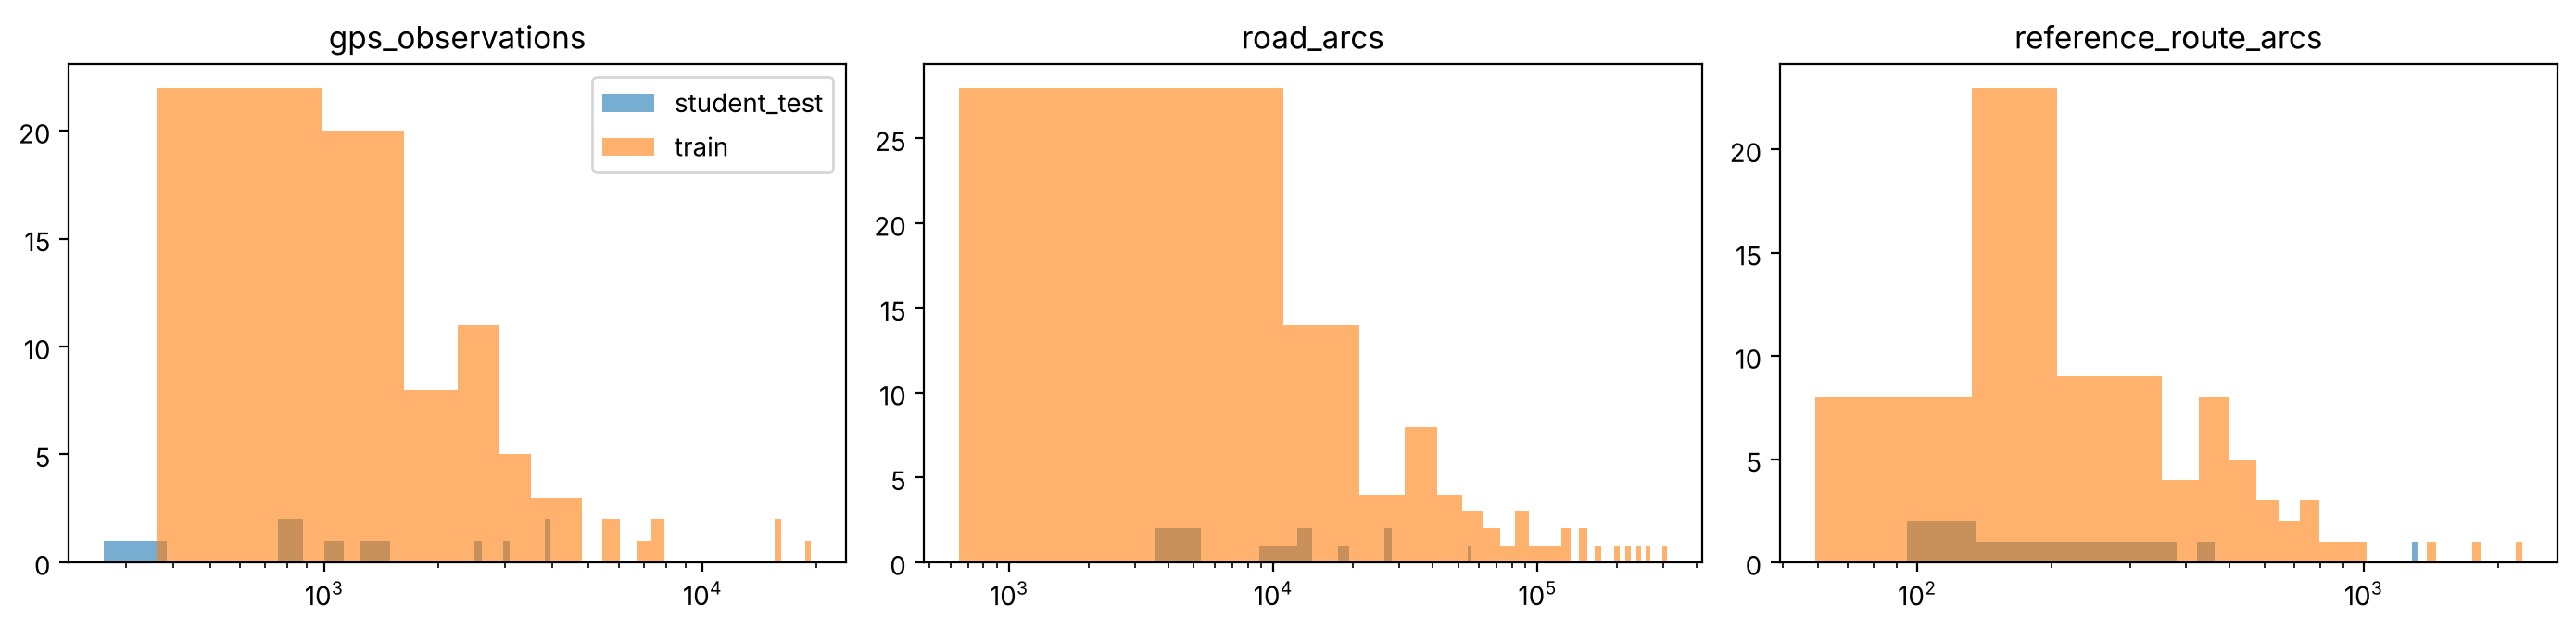

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["gps_observations", "road_arcs", "reference_route_arcs"]):
    for part, g in trip_summary.groupby("partition"):
        ax.hist(g[col], bins=30, alpha=0.6, label=part)
    ax.set_xscale("log")
    ax.set_title(col)
axes[0].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "trip_size_distributions.png", dpi=120)
plt.show()

## 5. Missing values, invalid coordinates, and timestamp checks

,trip,rows,missing_longitude,missing_latitude,missing_timestamp,invalid_coordinate_rows,duplicate_rows,non_increasing_timestamp_steps,median_time_gap_s,max_time_gap_s,gaps_gt_1s,gaps_gt_5s,gaps_gt_60s
0,train/00000001,1315,0,0,0,0,0,0,1.0,16.0,25,1,0
1,train/00000002,7243,0,0,0,0,0,0,1.0,160.0,184,78,5
2,train/00000003,821,0,0,0,0,0,0,1.0,2.0,3,0,0
3,train/00000004,1064,0,0,0,0,0,0,1.0,51.0,491,320,0
4,train/00000005,1045,0,0,0,0,0,0,1.0,1.0,0,0,0
5,train/00000006,1450,0,0,0,0,0,0,1.0,301.0,12,9,3
6,train/00000008,3093,0,0,0,0,0,0,1.0,2.0,1,0,0
7,train/00000010,2711,0,0,0,0,0,0,1.0,1.0,0,0,0
8,train/00000011,2828,0,0,0,0,0,0,1.0,909.0,1,1,1
9,train/00000012,1608,0,0,0,0,0,0,1.0,2.0,1,0,0


Overall missing/invalid summary:


,total
missing_longitude,0
missing_latitude,0
missing_timestamp,0
invalid_coordinate_rows,0
duplicate_rows,0
non_increasing_timestamp_steps,0
gaps_gt_1s,7550
gaps_gt_5s,1260
gaps_gt_60s,70


count    227487.000000
mean          2.086635
std         339.588483
min           1.000000
50%           1.000000
90%           1.000000
95%           1.000000
99%           3.000000
99.9%        20.000000
max      153064.000000
Name: time_gap_s, dtype: float64
Share of steps exactly 1 s: 0.9668


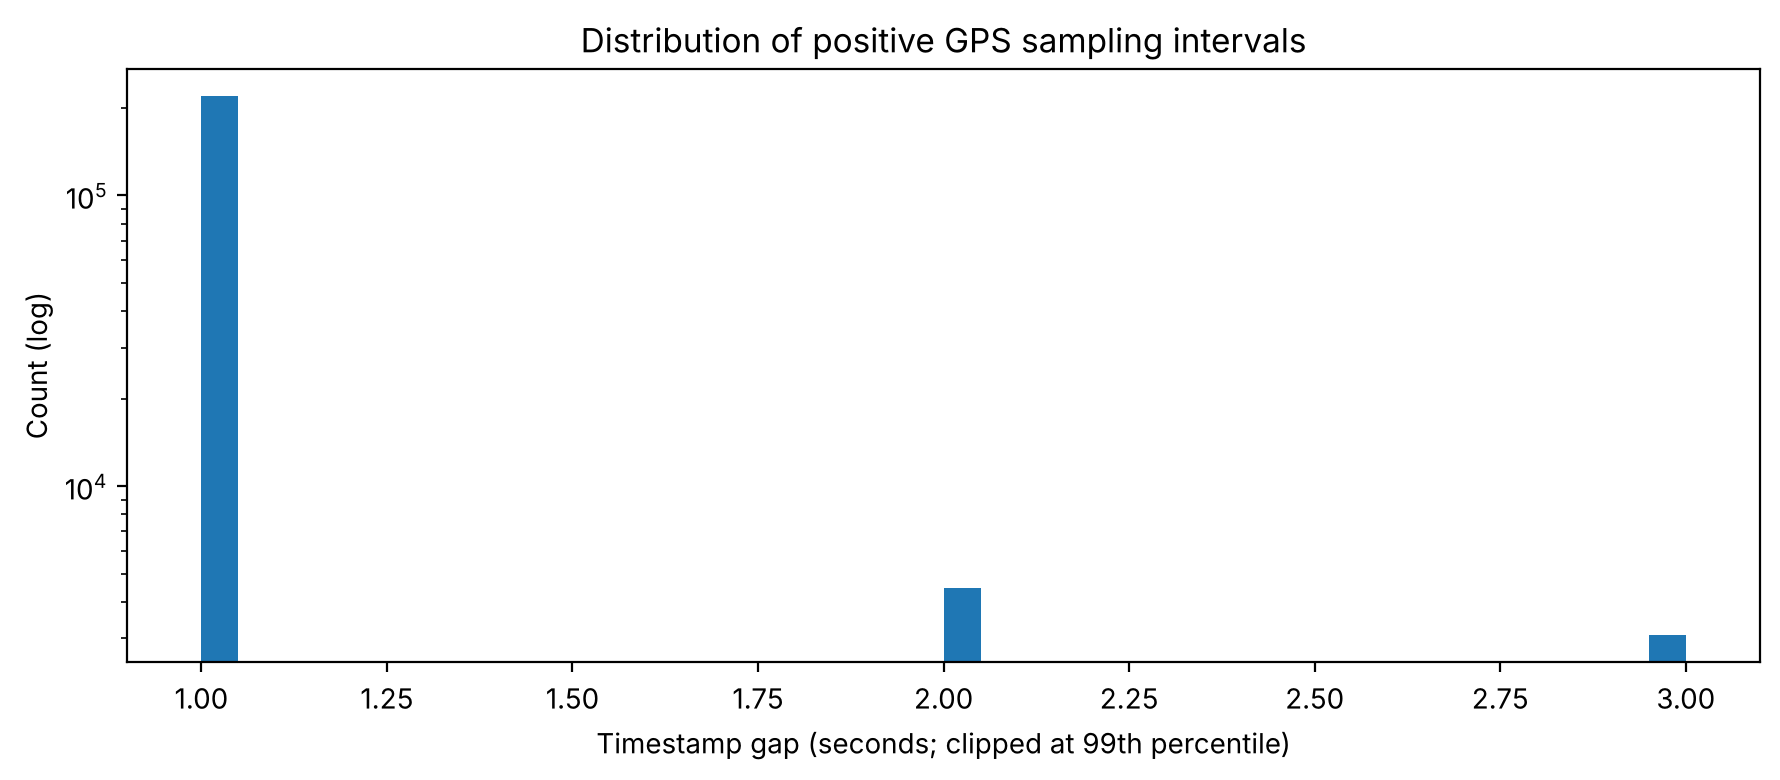

In [6]:
quality_rows = []
gap_frames = []
for key, trip in trips.items():
    track = trip.get("track")
    if track is None:
        continue
    t = track.apply(pd.to_numeric, errors="coerce")
    invalid_coord = (
        t["longitude"].isna() | t["latitude"].isna()
        | ~t["longitude"].between(-180, 180)
        | ~t["latitude"].between(-90, 90)
    )
    diffs = t["timestamp"].diff()
    quality_rows.append({
        "trip": key,
        "rows": len(t),
        "missing_longitude": int(t["longitude"].isna().sum()),
        "missing_latitude": int(t["latitude"].isna().sum()),
        "missing_timestamp": int(t["timestamp"].isna().sum()),
        "invalid_coordinate_rows": int(invalid_coord.sum()),
        "duplicate_rows": int(t.duplicated().sum()),
        "non_increasing_timestamp_steps": int((diffs <= 0).sum()),
        "median_time_gap_s": diffs[diffs > 0].median(),
        "max_time_gap_s": diffs.max(),
        "gaps_gt_1s": int((diffs > 1).sum()),
        "gaps_gt_5s": int((diffs > 5).sum()),
        "gaps_gt_60s": int((diffs > 60).sum()),
    })
    gap_frames.append(pd.DataFrame({"trip": key, "time_gap_s": diffs}))

quality = pd.DataFrame(quality_rows)
display(quality.head(10))
print("Overall missing/invalid summary:")
display(quality[[
    "missing_longitude", "missing_latitude", "missing_timestamp", "invalid_coordinate_rows",
    "duplicate_rows", "non_increasing_timestamp_steps", "gaps_gt_1s", "gaps_gt_5s", "gaps_gt_60s",
]].sum().to_frame("total"))

all_gaps = pd.concat(gap_frames, ignore_index=True)
valid_gaps = all_gaps.loc[all_gaps["time_gap_s"] > 0, "time_gap_s"].dropna()
print(valid_gaps.describe(percentiles=[.5, .9, .95, .99, .999]))
print("Share of steps exactly 1 s:", round((valid_gaps == 1).mean(), 4))

plt.figure(figsize=(9, 4))
plt.hist(valid_gaps.clip(upper=valid_gaps.quantile(.99)), bins=40)
plt.yscale("log")
plt.xlabel("Timestamp gap (seconds; clipped at 99th percentile)")
plt.ylabel("Count (log)")
plt.title("Distribution of positive GPS sampling intervals")
plt.tight_layout()
plt.savefig(OUT_DIR / "sampling_interval_hist.png", dpi=120)
plt.show()

Trips with the largest gaps (anomalies to keep in mind for the HMM):

In [7]:
display(quality.sort_values("max_time_gap_s", ascending=False)[
    ["trip", "rows", "max_time_gap_s", "gaps_gt_5s", "gaps_gt_60s"]
].head(10))

,trip,rows,max_time_gap_s,gaps_gt_5s,gaps_gt_60s
72,train/00000090,536,153064.0,20,1
61,train/00000078,2909,52810.0,124,1
55,train/00000069,2067,2658.0,2,2
16,train/00000021,15783,2161.0,2,2
8,train/00000011,2828,909.0,1,1
34,train/00000042,7739,670.0,45,17
64,train/00000081,3224,536.0,129,15
18,train/00000024,801,458.0,4,2
36,train/00000044,546,341.0,2,1
67,train/00000084,16031,312.0,4,2


## 6. GPS trajectory statistics and plots
Longitude/latitude are angles, so extents are also converted to kilometres (equirectangular approximation around each trip's centre).

In [8]:
EARTH_R_KM = 6371.0088
gps_stats = []
for key, trip in trips.items():
    t = trip.get("track")
    if t is None or t.empty:
        continue
    valid = t.dropna(subset=["longitude", "latitude"])
    lat0 = valid.latitude.mean()
    lon_rng = valid.longitude.max() - valid.longitude.min()
    lat_rng = valid.latitude.max() - valid.latitude.min()
    gps_stats.append({
        "trip": key,
        "min_lon": valid.longitude.min(), "max_lon": valid.longitude.max(),
        "min_lat": valid.latitude.min(), "max_lat": valid.latitude.max(),
        "mean_lon": valid.longitude.mean(), "mean_lat": lat0,
        "width_km": np.radians(lon_rng) * np.cos(np.radians(lat0)) * EARTH_R_KM,
        "height_km": np.radians(lat_rng) * EARTH_R_KM,
    })
gps_extent = pd.DataFrame(gps_stats)
display(gps_extent.head(10))
display(gps_extent[["width_km", "height_km"]].describe().round(2))

,trip,min_lon,max_lon,min_lat,max_lat,mean_lon,mean_lat,width_km,height_km
0,train/00000001,8.570524,8.647860,49.844053,50.211882,8.605599,50.088368,5.517410,40.900775
1,train/00000002,10.999961,11.050902,47.658344,47.695459,11.032568,47.683925,3.813380,4.127005
2,train/00000003,37.154202,37.201595,55.977135,56.007585,37.177362,55.987684,2.947812,3.385890
3,train/00000004,12.342280,12.459615,52.590308,52.718960,12.424218,52.641499,7.916969,14.305469
4,train/00000005,35.485577,35.544315,49.357581,49.613085,35.503261,49.486068,4.242997,28.410788
5,train/00000006,37.276002,37.317675,55.429164,55.487229,37.296376,55.454070,2.627692,6.456542
6,train/00000008,-86.584860,-86.567487,34.733275,34.753704,-86.576547,34.745333,1.587341,2.271604
7,train/00000010,37.357893,37.394790,55.786261,55.832857,37.383073,55.824642,2.304636,5.181246
8,train/00000011,59.647057,60.016866,56.041788,56.067535,59.853354,56.053894,22.962462,2.862940
9,train/00000012,44.044515,44.389906,36.175914,36.263587,44.250568,36.219526,30.984208,9.748806


,width_km,height_km
count,90.00,90.00
mean,13.55,11.68
std,15.77,14.16
min,0.85,0.87
25%,3.34,3.21
50%,6.73,5.25
75%,16.47,13.72
max,70.39,75.40


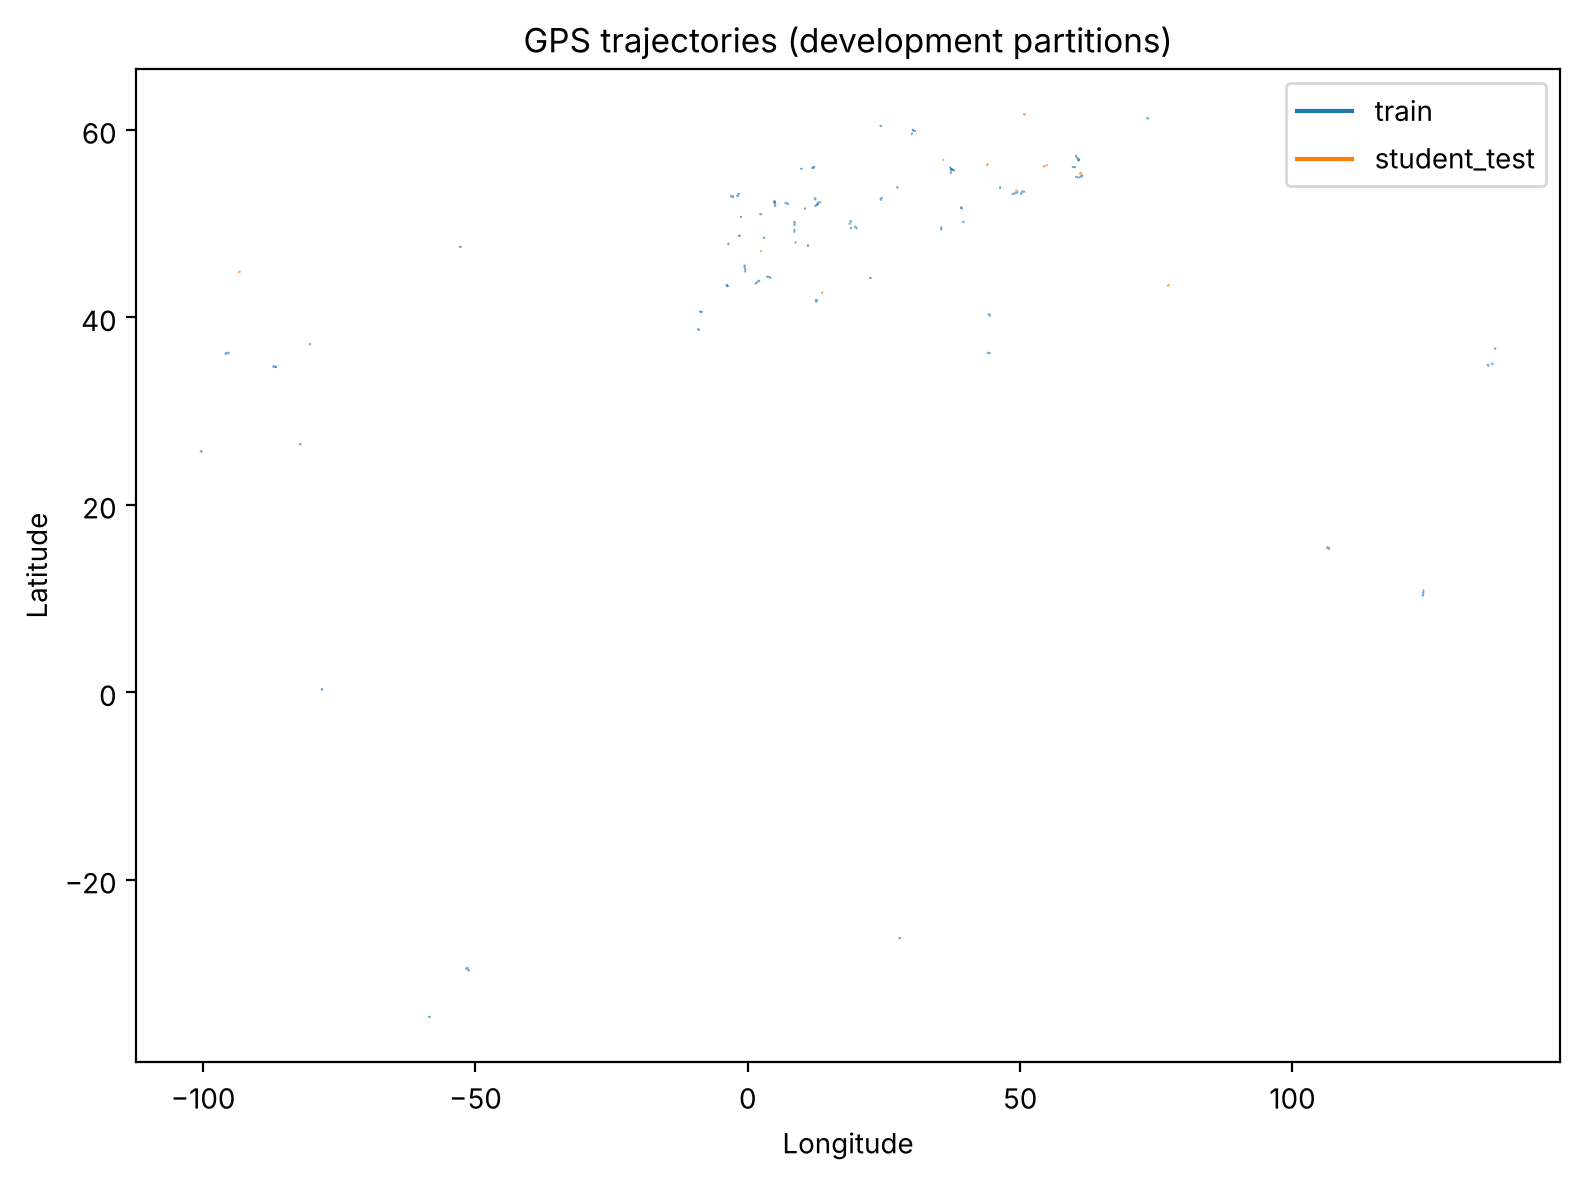

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for key, trip in trips.items():
    t = trip.get("track")
    if t is not None and len(t):
        ax.plot(t.longitude, t.latitude, linewidth=0.7, alpha=0.6,
                color="tab:blue" if trip["partition"] == "train" else "tab:orange")
ax.plot([], [], color="tab:blue", label="train")
ax.plot([], [], color="tab:orange", label="student_test")
ax.legend()
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("GPS trajectories (development partitions)")
plt.tight_layout()
plt.savefig(OUT_DIR / "all_trajectories.png", dpi=120)
plt.show()

## 7. Road-network statistics and connectivity
Arc row index is treated as `arc_id` and node row index as `node_id`, as in the dataset description. Directed weak components, isolated nodes, and how many arcs also exist in the reverse direction (two-way roads) are reported.

In [10]:
try:
    import networkx as nx
    NETWORKX_AVAILABLE = True
except ImportError:
    NETWORKX_AVAILABLE = False
    print("Install networkx to run connectivity analysis: pip install networkx")

network_rows = []
for key, trip in trips.items():
    nodes, arcs = trip.get("nodes"), trip.get("arcs")
    if nodes is None or arcs is None:
        continue
    a = arcs.apply(pd.to_numeric, errors="coerce").dropna().astype(int)
    valid = a[a.from_node_id.between(0, len(nodes) - 1) & a.to_node_id.between(0, len(nodes) - 1)]
    pairs = set(zip(valid.from_node_id, valid.to_node_id))
    row = {
        "trip": key, "nodes": len(nodes), "arcs": len(arcs),
        "valid_arcs": len(valid), "invalid_endpoint_arcs": len(a) - len(valid),
        "self_loops": int((valid.from_node_id == valid.to_node_id).sum()),
        "two_way_arc_share": round(np.mean([(v, u) in pairs for u, v in pairs]), 3),
    }
    if NETWORKX_AVAILABLE:
        G = nx.DiGraph()
        G.add_nodes_from(range(len(nodes)))
        G.add_edges_from(valid[["from_node_id", "to_node_id"]].itertuples(index=False, name=None))
        comps = list(nx.weakly_connected_components(G))
        row["weak_components"] = len(comps)
        row["isolated_nodes"] = nx.number_of_isolates(G)
        row["largest_component_share"] = round(max(len(c) for c in comps) / len(nodes), 3)
    network_rows.append(row)

network_summary = pd.DataFrame(network_rows)
display(network_summary.head(10))
display(network_summary.drop(columns="trip").describe().round(3))

,trip,nodes,arcs,valid_arcs,invalid_endpoint_arcs,self_loops,two_way_arc_share,weak_components,isolated_nodes,largest_component_share
0,train/00000001,88809,165790,165790,0,0,0.818,175,0,0.978
1,train/00000002,7936,16139,16139,0,0,0.997,14,0,0.977
2,train/00000003,9138,18028,18028,0,0,0.910,42,0,0.944
3,train/00000004,7350,15499,15499,0,0,0.976,12,0,0.987
4,train/00000005,898,1579,1579,0,0,0.816,3,0,0.989
5,train/00000006,3259,6757,6757,0,0,0.977,8,0,0.903
6,train/00000008,4995,10421,10421,0,0,0.905,13,0,0.984
7,train/00000010,8502,15715,15715,0,0,0.824,28,0,0.934
8,train/00000011,2649,5393,5393,0,0,0.998,2,0,0.997
9,train/00000012,16376,38599,38599,0,0,0.953,22,0,0.982


,nodes,arcs,valid_arcs,invalid_endpoint_arcs,self_loops,two_way_arc_share,weak_components,isolated_nodes,largest_component_share
count,90.000,90.000,90.000,90.0,90.000,90.000,90.000,90.0,90.000
mean,22490.822,45132.722,45132.722,0.0,0.267,0.922,37.200,0.0,0.968
std,30868.526,61920.285,61920.285,0.0,1.003,0.091,58.149,0.0,0.038
min,299.000,649.000,649.000,0.0,0.000,0.351,1.000,0.0,0.693
25%,3655.250,7282.750,7282.750,0.0,0.000,0.891,8.250,0.0,0.963
50%,9305.000,18761.500,18761.500,0.0,0.000,0.951,19.000,0.0,0.980
75%,26296.500,52913.250,52913.250,0.0,0.000,0.984,40.750,0.0,0.987
max,155003.000,307392.000,307392.000,0.0,8.000,1.000,421.000,0.0,1.000


## 8. Reference-route consistency checks
Structural checks only (valid ids, consecutive arcs connected). This does not claim the supplied route is error-free ground truth.

In [11]:
route_checks = []
for key, trip in trips.items():
    route, arcs = trip.get("route"), trip.get("arcs")
    if route is None or arcs is None:
        continue
    ids = pd.to_numeric(route.arc_id, errors="coerce").dropna().astype(int).to_numpy()
    ok = ids[(ids >= 0) & (ids < len(arcs))]
    frm, to = arcs.from_node_id.to_numpy(), arcs.to_node_id.to_numpy()
    connected = to[ok[:-1]] == frm[ok[1:]]
    route_checks.append({
        "trip": key,
        "route_length": len(ids),
        "invalid_arc_ids": int(len(ids) - len(ok)),
        "unique_route_arcs": len(set(ids)),
        "disconnected_steps": int((~connected).sum()),
    })
route_checks = pd.DataFrame(route_checks)
display(route_checks.head(10))
display(route_checks[["invalid_arc_ids", "disconnected_steps"]].sum().to_frame("total"))
display(route_checks[route_checks.disconnected_steps > 0])

,trip,route_length,invalid_arc_ids,unique_route_arcs,disconnected_steps
0,train/00000001,525,0,525,0
1,train/00000002,262,0,262,1
2,train/00000003,79,0,79,0
3,train/00000004,320,0,320,0
4,train/00000005,105,0,105,0
5,train/00000006,261,0,261,0
6,train/00000008,173,0,172,0
7,train/00000010,210,0,210,0
8,train/00000011,565,0,565,0
9,train/00000012,205,0,205,0


,total
invalid_arc_ids,0
disconnected_steps,14


,trip,route_length,invalid_arc_ids,unique_route_arcs,disconnected_steps
1,train/00000002,262,0,262,1
14,train/00000019,545,0,545,3
26,train/00000033,169,0,169,1
33,train/00000041,340,0,340,1
34,train/00000042,1440,0,1440,1
55,train/00000069,467,0,438,1
60,train/00000075,108,0,106,2
63,train/00000080,139,0,139,1
69,train/00000086,671,0,669,1
71,train/00000089,265,0,265,1


## 9. Folium interactive map for one representative trip
Raw GPS observations, the road network and the supplied reference route. Large networks are sampled for display only; the data are not modified.

In [12]:
try:
    import folium
    FOLIUM_AVAILABLE = True
except ImportError:
    FOLIUM_AVAILABLE = False
    print("Install folium: pip install folium")

selected_key = MAP_TRIP if MAP_TRIP in trips else next(
    (k for k, v in trips.items() if v["partition"] == MAP_PARTITION and v.get("track") is not None), None)
print("Selected trip:", selected_key)

if FOLIUM_AVAILABLE and selected_key:
    trip = trips[selected_key]
    track = trip["track"].dropna(subset=["longitude", "latitude"])
    n, a = trip["nodes"], trip["arcs"]
    nlat, nlon = n.latitude.to_numpy(), n.longitude.to_numpy()

    fmap = folium.Map(location=[track.latitude.mean(), track.longitude.mean()],
                      zoom_start=14, control_scale=True, tiles=None)
    # basemap is optional; if the tiles are blocked the data layers still show
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(fmap)

    # road network: only arcs near the trip, sampled if still large
    lat_lo, lat_hi = track.latitude.min() - 0.005, track.latitude.max() + 0.005
    lon_lo, lon_hi = track.longitude.min() - 0.005, track.longitude.max() + 0.005
    u, v = a.from_node_id.to_numpy(), a.to_node_id.to_numpy()
    inside = (nlat[u] > lat_lo) & (nlat[u] < lat_hi) & (nlon[u] > lon_lo) & (nlon[u] < lon_hi)
    arc_ids = np.flatnonzero(inside)[:: max(1, int(inside.sum()) // 5000)]
    road_group = folium.FeatureGroup(name="Road network", show=True)
    for i in arc_ids:
        folium.PolyLine([[nlat[u[i]], nlon[u[i]]], [nlat[v[i]], nlon[v[i]]]],
                        color="gray", weight=1, opacity=0.5, tooltip=f"arc {i}").add_to(road_group)
    road_group.add_to(fmap)

    route = trip.get("route")
    if route is not None:
        r = route.arc_id.to_numpy()
        path_nodes = np.append(u[r], v[r[-1]])
        ref_group = folium.FeatureGroup(name="Supplied reference route", show=True)
        folium.PolyLine(np.column_stack([nlat[path_nodes], nlon[path_nodes]]).tolist(),
                        color="green", weight=4, opacity=0.8, tooltip="Reference route").add_to(ref_group)
        ref_group.add_to(fmap)

    gps_group = folium.FeatureGroup(name="GPS observations", show=True)
    step = max(1, len(track) // 300)
    for lat, lon in track[["latitude", "longitude"]].to_numpy()[::step]:
        folium.CircleMarker([lat, lon], radius=2, color="blue", fill=True,
                            fill_opacity=0.8).add_to(gps_group)
    gps_group.add_to(fmap)

    folium.Marker(track.iloc[0][["latitude", "longitude"]].tolist(), tooltip="Trip start",
                  icon=folium.Icon(color="green", icon="play")).add_to(fmap)
    folium.Marker(track.iloc[-1][["latitude", "longitude"]].tolist(), tooltip="Trip end",
                  icon=folium.Icon(color="red", icon="stop")).add_to(fmap)

    folium.LayerControl(collapsed=False).add_to(fmap)
    fmap.fit_bounds([[track.latitude.min(), track.longitude.min()],
                     [track.latitude.max(), track.longitude.max()]])

    map_path = OUT_DIR / f"eda_map_{selected_key.split('/')[-1]}.html"
    fmap.save(map_path)
    print("Arcs drawn:", len(arc_ids), "of", len(a))
    print("Saved:", map_path)

Selected trip: train/00000005


Arcs drawn: 1473 of 1579
Saved: /home/user/PathSnap/results/eda/eda_map_00000005.html


Open the saved HTML file in a browser to view the map (`results/eda/`). In Colab/Jupyter you can also run `fmap` in a cell to show it inline.

## 10. Export EDA tables

In [13]:
inventory.drop(columns="path").to_csv(OUT_DIR / "file_inventory.csv", index=False)
trip_summary.to_csv(OUT_DIR / "trip_summary.csv", index=False)
quality.to_csv(OUT_DIR / "gps_quality_summary.csv", index=False)
gps_extent.to_csv(OUT_DIR / "gps_geographical_extent.csv", index=False)
network_summary.to_csv(OUT_DIR / "road_network_summary.csv", index=False)
route_checks.to_csv(OUT_DIR / "route_checks.csv", index=False)
print("EDA outputs saved to:", OUT_DIR)
for f in sorted(OUT_DIR.iterdir()):
    print(" ", f.name)

EDA outputs saved to: /home/user/PathSnap/results/eda
  all_trajectories.png
  eda_map_00000005.html
  file_inventory.csv
  gps_geographical_extent.csv
  gps_quality_summary.csv
  road_network_summary.csv
  route_checks.csv
  sampling_interval_hist.png
  trip_size_distributions.png
  trip_summary.csv


## 11. EDA Summary and Key Findings

All numbers below come from the outputs above (and the CSVs in `results/eda/`).

### 11.1 Dataset overview

- **Training:** 80 trips, **student testing:** 10 trips, 90 in total. Every trip has all four files (`.track`, `.nodes`, `.arcs`, `.route`), 360 files, about 94 MB.
- **227,577 GPS observations** in total (208,417 train, 19,160 student_test). Trip length ranges from 262 to 19,313 points (median about 1,500).
- Road networks vary a lot in size: 649 to 307,392 arcs per trip (median about 18,800).
- The trips are spread across many different cities and countries (e.g. around 8.6°E 50.1°N, 37°E 56°N, −86.6°E 34.7°N), so one global projection is not suitable. Distances should be computed in a local projection per trip (or geodesically). Trip extents are 0.85–70 km wide (median about 6.7 km).

### 11.2 Data quality

| Check | Result |
|---|---:|
| Missing longitude / latitude / timestamp | 0 / 0 / 0 |
| Invalid coordinate rows | 0 |
| Duplicate rows | 0 |
| Non-increasing timestamp steps | 0 |
| Invalid arc endpoints | 0 |
| Invalid route arc ids | 0 |

- Sampling is nominally 1 Hz: **96.7%** of steps are exactly 1 s, the 99th percentile is 3 s.
- There are 7,550 gaps over 1 s, 1,260 over 5 s and 70 over 60 s.
- A few trips have very large gaps: train/00000090 has a **153,064 s** gap (about 42 hours), train/00000078 has 52,810 s, and train/00000069 and train/00000021 have gaps of about 36–44 minutes. These look like separate recordings joined into one file, so the HMM should not force a connected path across them.

### 11.3 Road network

- Directed graph per trip, nodes = rows of `.nodes`, arcs = rows of `.arcs`. No isolated nodes.
- Most roads are two-way: on average **92%** of arcs also exist in the reverse direction. Train/00000080 is the exception (35%). For two-way roads the two arcs are at the same distance from a GPS point, so direction (heading) is needed to tell them apart.
- Networks are not always one connected piece: weak components per trip have a median of 19 and a maximum of 421, though the largest component holds about 97% of nodes on average. Small disconnected pieces need to be handled in the HMM transitions.
- A few arcs are self-loops (up to 8 in one trip).

### 11.4 Reference routes

- All route arc ids are valid, and consecutive route arcs are almost always connected (end node of one = start node of the next). There are only **14 disconnected steps** across 11 trips.
- 10 trips use some arc more than once (e.g. train/00000069 has 467 route arcs but 438 unique ones), so a route can revisit roads.
- Routes have no timestamps, so which GPS point belongs to which route arc must be worked out (done in P1's candidate/label step). P1 also found that in trips 33, 54 and the end of trip 2 the GPS is far (>100 m) from the reference route, so the reference route is not perfect ground truth.

### 11.5 Implications for the ML pipeline

1. Use a local metric projection per trip, since the trips are in many different places.
2. Candidate generation should look at road arcs near each GPS point; distance alone is not enough because of two-way roads, so heading difference is an important feature.
3. Time gaps (especially the >60 s ones) must be considered in HMM transitions; very long gaps should break or relax the connectivity constraint.
4. Road connectivity should drive the HMM transitions, with a fallback for disconnected components.
5. Group by trip in cross-validation (GroupKFold) so points from one trip never end up in both train and validation.
6. Student-test trips are for development comparisons only; evaluator-test data stays untouched.

### 11.6 Map

`results/eda/eda_map_00000005.html` shows train trip 00000005 with the GPS points, the nearby road network and the supplied reference route (layers can be toggled).